# 19 — Exact double-stratified graphical finite population sampling

**Prescribed inclusion probabilities → graphical segments → induced sampling design.**

This notebook constructs and rearranges a segmented GFS arrangement directly from
$X$ and $\pi$. The unit lengths are inputs; sample probabilities are derived only
**after** the vertical strips have been built. Every strip must have the required
margins for both classifications. Entropy is a diagnostic, never an objective.

Start with `SMALL`, read its intermediate tables and plots, then change just
`POPULATION` to `"MU284"` and **Restart Kernel → Run All**. Use the repository's
`.venv` kernel. Dependencies: NumPy, pandas, matplotlib, NetworkX, IPython.
If NetworkX is missing, install it in your kernel with `%pip install networkx`.
The notebook is self-contained; it does not call the repository's existing GFS optimizers.

In [1]:
POPULATION = "SMALL"     # switch to "MU284"
RANDOM_SEED = 12345
RUN_EXCHANGES = True
N_EXCHANGES = 20
VERBOSE = True

## 0. Imports and conventions

Unit vectors use zero-based array positions internally; displayed unit labels are
one-based. Columns of $X$ always list the G categories first, then the C categories.
`H` marks that boundary. All samples are binary arrays, and each strip stores its
positive height and its sample. The chosen flow is merely one feasible solution:
there is no scoring or entropy-based choice.

We use absolute tolerance $10^{-10}$ for reconstructed lengths. Residual arithmetic
uses NumPy's extended precision where available. Near-zero/one flow coordinates
are recognized using an arithmetic roundoff budget scaled by the remaining height,
rather than broadly rounding the prescribed $\pi$. Any final numerical tail is explicitly recorded and bounded below.

In [2]:
from pathlib import Path
from itertools import combinations
from time import perf_counter
import subprocess
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
import networkx as nx
from IPython.display import display, Markdown

TOL = 1e-10
BOUNDARY_TOL = 64 * np.finfo(float).eps
pd.set_option("display.precision", 6)

def locate_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "simulations").is_dir():
            return folder
    return Path.cwd()

## 1. The eight-unit teaching population

There are two units in each $(G,C)$ cell. Their prescribed lengths are
$(.7,.3,.6,.4,.4,.6,.3,.7)$. The four category totals are all 2, so every
sample must select two units from each G category and two from each C category.
Each family of margins totals 4; **adding both families counts every unit twice**.
Thus the sample size is 4, not 8.

The following helpers also work for MU284. Each row of $X$ has exactly two ones.
We validate integrality, compatible family totals, probability bounds and matrix
structure before construction. Integer margins alone do not make an arbitrary
bounded raking problem feasible; the later calibration must actually pass its checks.

In [3]:
def make_small_population():
    return pd.DataFrame({
        "unit": np.arange(1, 9),
        "G": ["G1"] * 4 + ["G2"] * 4,
        "C": ["C1", "C1", "C2", "C2"] * 2,
        "pi": [.7, .3, .6, .4, .4, .6, .3, .7],
    })


def build_disjunctive_matrix(population):
    assert not population[["G", "C"]].isna().any().any()
    g_levels = sorted(population["G"].unique())
    c_levels = sorted(population["C"].unique())
    g_columns = [(population["G"].to_numpy() == g).astype(int) for g in g_levels]
    c_columns = [(population["C"].to_numpy() == c).astype(int) for c in c_levels]
    X = np.column_stack(g_columns + c_columns)
    H = len(g_levels)
    labels = [f"G={g}" for g in g_levels] + [f"C={c}" for c in c_levels]
    assert np.all(X[:, :H].sum(axis=1) == 1)
    assert np.all(X[:, H:].sum(axis=1) == 1)
    assert np.all(X.sum(axis=1) == 2)
    return X, labels, H


def check_integer_margins(X, pi, H, tol=TOL):
    X = np.asarray(X)
    pi = np.asarray(pi, dtype=np.longdouble)
    assert X.ndim == 2 and pi.shape == (len(X),)
    assert 0 < H < X.shape[1]
    assert np.all((X == 0) | (X == 1))
    assert np.all(X[:, :H].sum(axis=1) == 1)
    assert np.all(X[:, H:].sum(axis=1) == 1)
    assert np.all(np.isfinite(pi)) and np.all((pi >= 0) & (pi <= 1))
    expected = X.T @ pi
    m = np.rint(expected).astype(int)
    assert np.max(np.abs(expected - m)) <= tol, "Prescribed pi has noninteger margins"
    assert m[:H].sum() == m[H:].sum()
    assert abs(pi.sum() - m[:H].sum()) <= tol
    return m

### MU284 preparation helpers (read now or return in section 9)

The same workflow needs a loader before selecting the population. Loading order:
local **original 284-row** `MU284.csv`, then R's `sampling::MU284` via Rscript,
then rpy2 if available. A 281-row filtered file is never silently substituted.
The bundled original CSV is in `simulations/populations/store/MU284.csv`, exported
from the installed R `sampling` package, version 2.11. Source:
[CRAN sampling](https://cran.r-project.org/package=sampling),
[package data mirror](https://github.com/cran/sampling/tree/master/data).

For another checkout, place the original `MU284.csv` beside this notebook or at
that store path. Missing MU284 data skips only the MU284 workflow; the SMALL
teaching example and final stress tests still run. Malformed available data raises
an error rather than pretending the data are missing.

R's default quantiles use type 7, equivalent to NumPy's linear interpolation.
`pd.cut(..., right=True, include_lowest=True)` assigns internal boundary values
to the lower interval, matching `cut` in R. Tied quartile boundaries are reported
as an error; they are not silently replaced by a different categorization.

For integer margins we round, then add or remove counts in order of the remaining
fractional residuals, preserving the total 100 in **each** classification. Raking
alternates G and C rescaling. It never clips calibrated probabilities to one:
if the bounded check fails, the requested calibration is not valid for this algorithm.

In [4]:
def load_mu284(root=None):
    root = locate_project_root() if root is None else Path(root)
    candidates = [Path.cwd() / "MU284.csv", root / "MU284.csv",
                  root / "simulations/jupyters/MU284.csv",
                  root / "simulations/populations/store/MU284.csv"]

    def validate(frame, source):
        frame = frame.copy()
        frame.columns = frame.columns.str.strip().str.upper()
        if len(frame) != 284:
            raise ValueError(f"{source}: expected original MU284 with 284 rows, got {len(frame)}")
        if not {"REG", "P85"}.issubset(frame.columns):
            raise ValueError(f"{source}: MU284 needs REG and P85 columns")
        assert not frame[["REG", "P85"]].isna().any().any()
        return frame, source

    for path in dict.fromkeys(candidates):
        if path.is_file():
            return validate(pd.read_csv(path), str(path.resolve()))

    if shutil.which("Rscript"):
        script = ('if (!requireNamespace("sampling", quietly=TRUE)) quit(status=2); '
                  'data(MU284, package="sampling"); '
                  'write.csv(MU284, stdout(), row.names=FALSE)')
        result = subprocess.run(["Rscript", "-e", script], capture_output=True,
                                text=True, timeout=60)
        if result.returncode == 0:
            from io import StringIO
            return validate(pd.read_csv(StringIO(result.stdout)), "R sampling::MU284")

    try:
        import rpy2.robjects as ro
        from rpy2.robjects import pandas2ri
        from rpy2.robjects.conversion import localconverter
    except (ImportError, ValueError, OSError):
        ro = None
    if ro is not None:
        available = bool(ro.r('requireNamespace("sampling", quietly=TRUE)')[0])
        if available:
            ro.r('data(MU284, package="sampling")')
            with localconverter(ro.default_converter + pandas2ri.converter):
                frame = ro.conversion.rpy2py(ro.globalenv["MU284"])
            return validate(frame, "R sampling::MU284 via rpy2")
    raise FileNotFoundError(
        f"MU284 unavailable. Place the ORIGINAL 284-row MU284.csv at "
        f"{root / 'simulations/populations/store/MU284.csv'} or beside this notebook. "
        "Alternatively install R's sampling package. SMALL needs no MU284 data."
    )


def make_mu284_categories(frame):
    frame = frame.copy().reset_index(drop=True)
    values = pd.to_numeric(frame["P85"], errors="raise").to_numpy()
    assert np.all(np.isfinite(values))
    breaks = np.quantile(values, [0, .25, .5, .75, 1], method="linear")
    if np.any(np.diff(breaks) <= 0):
        raise ValueError(f"Non-distinct P85 quartiles: {breaks}")
    frame["CAT"] = pd.cut(values, bins=breaks, labels=["CAT1", "CAT2", "CAT3", "CAT4"],
                          right=True, include_lowest=True)
    frame["G"] = frame["REG"]
    frame["C"] = frame["CAT"].astype(str)
    frame["unit"] = np.arange(1, len(frame) + 1)
    assert frame["REG"].nunique() == 8 and frame["CAT"].nunique() == 4
    assert not frame["CAT"].isna().any()
    return frame, breaks


def round_margins(expected, total):
    expected = np.asarray(expected, dtype=float)
    assert np.all(expected >= 0) and abs(expected.sum() - total) <= TOL
    rounded = np.rint(expected).astype(int)
    while rounded.sum() != total:
        residuals = expected - rounded
        if rounded.sum() < total:
            rounded[int(np.argmax(residuals))] += 1
        else:
            residuals[rounded == 0] = np.inf
            rounded[int(np.argmin(residuals))] -= 1
    assert rounded.sum() == total and np.all(rounded >= 0)
    return rounded


def rake_pi_to_integer_margins(X, pi_init, m, H, tol=None, max_iter=10000):
    pi = np.asarray(pi_init, dtype=np.longdouble).copy()
    # Sum roundoff depends on dtype and population size; retain a tight target
    # while allowing platforms whose longdouble is the same as float64.
    if tol is None:
        tol = max(1e-16, 8 * len(pi) * np.finfo(np.longdouble).eps)
    assert 0 < tol < TOL
    m = np.asarray(m, dtype=int)
    assert m[:H].sum() == m[H:].sum()
    history = []
    for iteration in range(1, max_iter + 1):
        for category_family in (range(H), range(H, X.shape[1])):
            for column in category_family:
                members = X[:, column].astype(bool)
                current = pi[members].sum()
                target = m[column]
                if target == 0:
                    pi[members] = 0
                elif current <= 0:
                    raise ValueError(f"Raking infeasible at column {column}: zero support")
                else:
                    pi[members] *= target / current
        error = float(np.max(np.abs(X.T @ pi - m)))
        history.append({"iteration": iteration, "margin_error": error,
                        "min_pi": pi.min(), "max_pi": pi.max(), "tolerance": float(tol)})
        if error <= tol:
            if np.any(pi < 0) or np.any(pi > 1):
                raise ValueError("Raking converged but pi is outside [0,1]; do not clip it")
            np.testing.assert_allclose(X.T @ pi, m, atol=TOL, rtol=0)
            return pi, pd.DataFrame(history)
    raise RuntimeError(f"Raking did not converge: final margin error {error:.3g}")

### Select the inputs with the single population switch

For SMALL the exact requested dataframe and all dummy columns are displayed.
For MU284 the category-level table is compact. No sample probabilities have been
specified in either branch. Yves's example rounded its category counts and used
`nh[7] = nh[7] + 1` for its particular ordering; our explicit residual adjustment
makes the total constraint independent of that ordering.

In [5]:
assert POPULATION in {"SMALL", "MU284"}
assert isinstance(N_EXCHANGES, int) and N_EXCHANGES >= 0
root = locate_project_root()
workflow_start = perf_counter()
data_available = True
raking_history = None

if POPULATION == "SMALL":
    population = make_small_population()
    X, margin_labels, H = build_disjunctive_matrix(population)
    pi = population["pi"].to_numpy()
    m = check_integer_margins(X, pi, H)
else:
    try:
        raw_mu284, data_source = load_mu284(root)
    except FileNotFoundError as error:
        data_available = False
        print(error)
        print("Skipping MU284 construction; the final synthetic stress tests still run.")
    if data_available:
        population, quartile_breaks = make_mu284_categories(raw_mu284)
        X, margin_labels, H = build_disjunctive_matrix(population)
        assert X.shape == (284, 12) and H == 8
        pi_init = np.full(len(population), 100 / len(population))
        m_init = X.T @ pi_init
        # Yves's particular R ordering used: nh = round(nhinit); nh[7] = nh[7] + 1.
        m = np.r_[round_margins(m_init[:H], 100), round_margins(m_init[H:], 100)]
        pi, raking_history = rake_pi_to_integer_margins(X, pi_init, m, H)
        population["pi"] = pi
        print("Data source:", data_source)
        print("P85 quartile boundaries:", quartile_breaks)
        display(pd.DataFrame({"category": margin_labels, "population_size": X.sum(axis=0),
                              "initial_expected_count": m_init, "integer_target": m,
                              "calibrated_count": X.T @ pi}))
        print(f"Raking: {len(raking_history)} iterations, "
              f"min(pi)={pi.min():.8f}, max(pi)={pi.max():.8f}, "
              f"max margin error={np.max(np.abs(X.T @ pi - m)):.3g}")
        check_integer_margins(X, pi, H)

if data_available:
    N = len(population)
    n = int(m[:H].sum())
    pi_original = pi.copy()
    print(f"N={N}, n={n}, sum(pi)={pi.sum():.12f}")
    if POPULATION == "SMALL":
        display(population[["unit", "G", "C", "pi"]])
        display(pd.DataFrame(X, index=population["unit"], columns=margin_labels))
        display(pd.DataFrame({"category": margin_labels, "X.T @ pi": X.T @ pi, "target m": m}))
        assert np.array_equal(m, [2, 2, 2, 2])
        assert abs(pi.sum() - 4) < TOL

N=8, n=4, sum(pi)=4.000000000000


,unit,G,C,pi
0,1,G1,C1,0.7
1,2,G1,C1,0.3
2,3,G1,C2,0.6
3,4,G1,C2,0.4
4,5,G2,C1,0.4
5,6,G2,C1,0.6
6,7,G2,C2,0.3
7,8,G2,C2,0.7


,G=G1,G=G2,C=C1,C=C2
unit,,,,
1,1,0,1,0
2,1,0,1,0
3,1,0,0,1
4,1,0,0,1
5,0,1,1,0
6,0,1,1,0
7,0,1,0,1
8,0,1,0,1


,category,X.T @ pi,target m
0,G=G1,2.0,2
1,G=G2,2.0,2
2,C=C1,2.0,2
3,C=C2,2.0,2


## 2. Construct strips directly from the residual lengths

Initially $L=1$ and $r=\pi$. The remaining conditional lengths are $q=r/L$.
At each step the invariant is $X^T r=Lm$, or $X^T q=m$.

**Step A — one feasible exact sample.** Treat each unit as an edge from its G
category to its C category. Forced units ($q_k=1$) are selected first and subtract
one from both endpoint demands. Forbidden units ($q_k=0$) are excluded.
Remaining demands are integers. A maximum flow must fill every remaining demand.

NetworkX's simple `DiGraph` cannot hold distinct parallel unit edges directly.
We therefore insert a **unit node** on each edge: `G → unit → C`, each arc with
capacity 1. Units sharing a cell remain separately selectable. This is the same
bipartite b-matching feasibility problem. General construction never enumerates
samples; only the independent eight-unit checker below does so.

In [6]:
def find_exact_sample_flow(X, q, m, H, rng=None, boundary_tol=BOUNDARY_TOL):
    q = np.asarray(q, dtype=float)
    m = np.asarray(m, dtype=int)
    assert q.shape == (len(X),) and np.all(np.isfinite(q))
    assert np.all(q >= -boundary_tol) and np.all(q <= 1 + boundary_tol)
    assert m[:H].sum() == m[H:].sum()
    g_index = np.argmax(X[:, :H], axis=1)
    c_index = np.argmax(X[:, H:], axis=1)
    forced = q >= 1 - boundary_tol
    forbidden = q <= boundary_tol
    sample = forced.astype(int)
    remaining = m - X.T @ sample
    if np.any(remaining < 0):
        raise ValueError("Flow infeasible: forced units exceed a category demand")
    if remaining[:H].sum() != remaining[H:].sum():
        raise ValueError("Flow infeasible: unequal residual demand totals")

    graph = nx.DiGraph()
    source, sink = ("source",), ("sink",)
    graph.add_nodes_from([source, sink])
    for g, demand in enumerate(remaining[:H]):
        graph.add_edge(source, ("G", g), capacity=int(demand))
    for c, demand in enumerate(remaining[H:]):
        graph.add_edge(("C", c), sink, capacity=int(demand))
    available = np.flatnonzero(~forced & ~forbidden)
    if rng is not None:
        available = rng.permutation(available)
    for k in available:
        unit = ("unit", int(k))
        graph.add_edge(("G", int(g_index[k])), unit, capacity=1)
        graph.add_edge(unit, ("C", int(c_index[k])), capacity=1)

    required = int(remaining[:H].sum())
    if required:
        value, flow = nx.maximum_flow(graph, source, sink, flow_func=nx.algorithms.flow.edmonds_karp)
        if value != required:
            raise ValueError(f"Flow infeasible: filled {value} of {required} required unit edges")
        for k in available:
            sample[k] = int(flow[("G", int(g_index[k]))][("unit", int(k))])
    assert np.all(sample[forced] == 1) and np.all(sample[forbidden] == 0)
    assert np.all((sample == 0) | (sample == 1))
    np.testing.assert_array_equal(X.T @ sample, m)
    return sample


def brute_force_check_small(X, q, m, sample):
    assert len(q) <= 8, "Enumeration is only an eight-unit independent checker"
    forced = q >= 1 - BOUNDARY_TOL
    forbidden = q <= BOUNDARY_TOL
    feasible = []
    for bits in range(2 ** len(q)):
        candidate = np.array([(bits >> k) & 1 for k in range(len(q))])
        if (np.all(candidate[forced] == 1) and np.all(candidate[forbidden] == 0)
                and np.array_equal(X.T @ candidate, m)):
            feasible.append(candidate)
    assert feasible, "Independent enumeration found no feasible sample"
    assert any(np.array_equal(candidate, sample) for candidate in feasible)
    return len(feasible)

**Step B — the largest safe strip.** For a chosen sample $s$, set

$$\alpha=\min\left(\min_{s_k=1}q_k,\;\min_{s_k=0}(1-q_k)\right),\qquad h=\alpha L.$$

An empty minimum imposes no restriction. If $q$ is already binary, the entire
remaining height is used. Otherwise update $r\leftarrow r-hs$ and
$L\leftarrow L-h$. For $\alpha<1$,
$q'=(q-\alpha s)/(1-\alpha)$ stays in $[0,1]^N$ and satisfies $X^Tq'=m$.
At least one fractional coordinate reaches a boundary. Existing 0/1 coordinates
stay fixed because the flow respects them. This explains why the construction
should finish in at most $N+1$ strips in exact arithmetic.

**Numerical convention:** We assert the residual invariant to absolute tolerance
$10^{-10}$. For the conditional invariant we scale the input/roundoff error budget
by $1/L$, and retain the measured error and allowed tolerance in every trace record.
Boundary recognition also scales the arithmetic roundoff budget by $1/L$; this avoids
mistaking magnified numerical noise for a genuinely fractional coordinate. If a positive tail $L\leq10^{-10}$ remains, it is assigned to the
last already exact sample and logged as `numerical_tail`. It can change any length
by at most that height; the final length checks still enforce $10^{-10}$.
This convention does not change any sample's integer margins. It is an explicitly
bounded floating-point approximation, not a claim of symbolic exactness.

In [7]:
def reconstruct_pi(strips):
    assert len(strips) > 0
    samples = np.stack([strip["sample"] for strip in strips])
    heights = np.array([strip["height"] for strip in strips], dtype=np.longdouble)
    return np.asarray(heights @ samples, dtype=float)


def verify_gfs(strips, X, pi, m, H, tol=TOL):
    heights = np.array([strip["height"] for strip in strips], dtype=float)
    samples = np.stack([strip["sample"] for strip in strips])
    assert np.all(np.isfinite(heights)) and np.all(heights > 0)
    assert abs(heights.sum() - 1) <= tol
    assert samples.shape[1] == len(pi)
    assert np.all((samples == 0) | (samples == 1))
    np.testing.assert_array_equal(samples @ X, np.tile(m, (len(strips), 1)))
    sample_size = int(np.sum(m[:H]))
    assert np.all(samples.sum(axis=1) == sample_size)
    assert abs(np.sum(pi) - sample_size) <= tol
    reconstructed = reconstruct_pi(strips)
    error = float(np.max(np.abs(reconstructed - pi)))
    assert error <= tol, f"Reconstructed pi error {error:.3g} exceeds {tol}"
    return {"strips": len(strips), "total_height": heights.sum(),
            "exact_margins_all_strips": True, "binary_all_samples": True,
            "positive_all_heights": True, "sample_size": sample_size,
            "max_pi_error": error}


def construct_exact_gfs(X, pi, m, H, seed=12345, check_small=False):
    pi = np.asarray(pi, dtype=np.longdouble)
    checked_m = check_integer_margins(X, pi, H)
    np.testing.assert_array_equal(checked_m, m)
    rng = np.random.default_rng(seed)
    residual = np.asarray(pi, dtype=np.longdouble).copy()
    remaining_height = np.longdouble(1)
    # A fixed residual error is magnified by 1/L in conditional coordinates.
    input_margin_error = np.max(np.abs(X.T @ residual - m))
    arithmetic_budget = 32 * len(pi) * np.finfo(np.longdouble).eps
    residual_budget = max(input_margin_error + arithmetic_budget, np.finfo(np.longdouble).eps)
    assert residual_budget <= TOL
    strips, trace = [], []
    for iteration in range(1, len(pi) + 3):
        if remaining_height <= TOL and strips:
            if remaining_height > 0:
                strips[-1]["height"] += float(remaining_height)
                trace[-1]["numerical_tail"] = float(remaining_height)
            remaining_height = np.longdouble(0)
            break
        q = residual / remaining_height
        conditional_tol = float(max(TOL, residual_budget / remaining_height))
        boundary_tol = float(max(BOUNDARY_TOL, arithmetic_budget / remaining_height))
        margin_error_q = float(np.max(np.abs(X.T @ q - m)))
        np.testing.assert_allclose(X.T @ residual, remaining_height * m, atol=TOL, rtol=0)
        np.testing.assert_allclose(X.T @ q, m, atol=conditional_tol, rtol=0)
        assert np.all(q >= -boundary_tol) and np.all(q <= 1 + boundary_tol)
        q = np.clip(q, 0, 1)
        sample = find_exact_sample_flow(X, q, m, H, rng=rng, boundary_tol=boundary_tol)
        feasible_count = brute_force_check_small(X, q, m, sample) if check_small else None
        fractional = (q > boundary_tol) & (q < 1 - boundary_tol)
        if not np.any(fractional):
            alpha = np.longdouble(1)
        else:
            selected_limits = q[sample == 1]
            absent_limits = 1 - q[sample == 0]
            limits = np.r_[selected_limits, absent_limits]
            alpha = np.min(limits)
        assert 0 < alpha <= 1
        height = alpha * remaining_height
        previous_height = remaining_height
        residual = residual - height * sample
        remaining_height = remaining_height - height
        assert np.all(residual >= -TOL)
        assert np.all(residual <= remaining_height + TOL)
        if remaining_height > TOL:
            q_after = np.clip(residual / remaining_height, 0, 1)
            next_boundary_tol = max(BOUNDARY_TOL, float(arithmetic_budget / remaining_height))
            became_zero = np.flatnonzero(fractional & (q_after <= next_boundary_tol)) + 1
            became_one = np.flatnonzero(fractional & (q_after >= 1 - next_boundary_tol)) + 1
            assert len(became_zero) + len(became_one) > 0
        else:
            q_after = None
            became_zero = np.array([], dtype=int)
            became_one = np.array([], dtype=int)
        strips.append({"height": float(height), "sample": sample.copy()})
        trace.append({"iteration": iteration, "L": float(previous_height),
                      "q": np.asarray(q, dtype=float), "sample": sample.copy(),
                      "margins": X.T @ sample, "alpha": float(alpha), "height": float(height),
                      "residual": np.asarray(residual, dtype=float).copy(),
                      "L_after": float(remaining_height), "q_after": q_after,
                      "became_zero": became_zero, "became_one": became_one,
                      "feasible_sample_count": feasible_count, "numerical_tail": 0.0,
                      "conditional_margin_error": margin_error_q, "conditional_tolerance": conditional_tol})
        if remaining_height == 0:
            break
    else:
        raise RuntimeError("Construction exceeded the boundary-elimination iteration bound")
    assert remaining_height == 0
    verify_gfs(strips, X, pi, m, H)
    return strips, trace


def print_construction_trace(trace, unit_labels):
    for step in trace:
        print(f"Iteration {step['iteration']} | L={step['L']:.12g} | "
              f"alpha={step['alpha']:.12g} | h={step['height']:.12g} | "
              f"L_after={step['L_after']:.12g}")
        display(pd.DataFrame({"unit": unit_labels, "q before": step["q"],
                              "selected s": step["sample"], "residual r after": step["residual"]}))
        print("X.T @ s =", step["margins"])
        print("New q=0 units:", step["became_zero"].tolist(),
              "| New q=1 units:", step["became_one"].tolist())
        if step["q_after"] is None:
            print("Terminal strip: no remaining conditional vector (L is zero or a numerical tail).")
        if step["feasible_sample_count"] is not None:
            print("Independent eight-unit enumeration: feasible samples =", step["feasible_sample_count"])
        if step["numerical_tail"]:
            print("Numerical tail assigned to this sample:", step["numerical_tail"])

In [8]:
if data_available:
    construction_start = perf_counter()
    initial_strips, construction_trace = construct_exact_gfs(
        X, pi_original, m, H, seed=RANDOM_SEED, check_small=(POPULATION == "SMALL"))
    construction_seconds = perf_counter() - construction_start
    if POPULATION == "SMALL" and VERBOSE:
        print_construction_trace(construction_trace, population["unit"].to_numpy())
    else:
        display(pd.DataFrame([{key: step[key] for key in ["iteration", "L", "alpha", "height", "L_after"]}
                              for step in construction_trace]).head(12))
        print("Full residual trace is retained in construction_trace.")
    print(f"Constructed {len(initial_strips)} strips in {construction_seconds:.4f} seconds.")

Iteration 1 | L=1 | alpha=0.3 | h=0.3 | L_after=0.7


,unit,q before,selected s,residual r after
0,1,0.7,1,0.4
1,2,0.3,0,0.3
2,3,0.6,0,0.6
3,4,0.4,1,0.1
4,5,0.4,1,0.1
5,6,0.6,0,0.6
6,7,0.3,1,0.0
7,8,0.7,0,0.7


X.T @ s = [2 2 2 2]
New q=0 units: [7] | New q=1 units: [8]
Independent eight-unit enumeration: feasible samples = 18
Iteration 2 | L=0.7 | alpha=0.142857142857 | h=0.1 | L_after=0.6


,unit,q before,selected s,residual r after
0,1,0.571429,0,4.000000e-01
1,2,0.428571,1,2.000000e-01
2,3,0.857143,1,5.000000e-01
3,4,0.142857,0,1.000000e-01
4,5,0.142857,1,6.776264e-21
5,6,0.857143,0,6.000000e-01
6,7,0.000000,0,0.000000e+00
7,8,1.000000,1,6.000000e-01


X.T @ s = [2 2 2 2]
New q=0 units: [5] | New q=1 units: [6]
Independent eight-unit enumeration: feasible samples = 8
Iteration 3 | L=0.6 | alpha=0.333333333333 | h=0.2 | L_after=0.4


,unit,q before,selected s,residual r after
0,1,6.666667e-01,0,4.000000e-01
1,2,3.333333e-01,1,0.000000e+00
2,3,8.333333e-01,1,3.000000e-01
3,4,1.666667e-01,0,1.000000e-01
4,5,1.129377e-20,0,6.776264e-21
5,6,1.000000e+00,1,4.000000e-01
6,7,0.000000e+00,0,0.000000e+00
7,8,1.000000e+00,1,4.000000e-01


X.T @ s = [2 2 2 2]
New q=0 units: [2] | New q=1 units: [1]
Independent eight-unit enumeration: feasible samples = 4
Iteration 4 | L=0.4 | alpha=0.75 | h=0.3 | L_after=0.1


,unit,q before,selected s,residual r after
0,1,1.000000e+00,1,1.000000e-01
1,2,0.000000e+00,0,0.000000e+00
2,3,7.500000e-01,1,0.000000e+00
3,4,2.500000e-01,0,1.000000e-01
4,5,1.694066e-20,0,6.776264e-21
5,6,1.000000e+00,1,1.000000e-01
6,7,0.000000e+00,0,0.000000e+00
7,8,1.000000e+00,1,1.000000e-01


X.T @ s = [2 2 2 2]
New q=0 units: [3] | New q=1 units: [4]
Independent eight-unit enumeration: feasible samples = 2
Iteration 5 | L=0.1 | alpha=1 | h=0.1 | L_after=0


,unit,q before,selected s,residual r after
0,1,1.000000e+00,1,-5.551115e-17
1,2,0.000000e+00,0,0.000000e+00
2,3,0.000000e+00,0,0.000000e+00
3,4,1.000000e+00,1,0.000000e+00
4,5,6.776264e-20,0,6.776264e-21
5,6,1.000000e+00,1,0.000000e+00
6,7,0.000000e+00,0,0.000000e+00
7,8,1.000000e+00,1,-5.551115e-17


X.T @ s = [2 2 2 2]
New q=0 units: [] | New q=1 units: []
Terminal strip: no remaining conditional vector (L is zero or a numerical tail).
Independent eight-unit enumeration: feasible samples = 1
Constructed 5 strips in 0.0335 seconds.


## 3. Verify and tabulate the graphical arrangement

A strip covers $[\text{lower}_y,\text{upper}_y)$; the last strip includes $y=1$.
This boundary convention makes **every** line have a single sample, including
strip boundaries (a uniform random line lands on a boundary with probability zero).
We do not count both adjoining samples at a boundary.

Check A: heights total 1. Check B: every strip has exactly $m$.
Check C: $\sum_t h_t s^{(t)}=\pi$. Check D: every sample has the integer size
$\sum_k\pi_k$. Bounds and binary indicators are also checked.

In [9]:
def strip_table(strips, unit_labels=None):
    if unit_labels is None:
        unit_labels = np.arange(1, len(strips[0]["sample"]) + 1)
    lower = 0.0
    rows = []
    for t, strip in enumerate(strips, start=1):
        upper = lower + strip["height"]
        rows.append({"strip": t, "lower_y": lower, "upper_y": upper,
                     "height": strip["height"],
                     "selected units": tuple(np.asarray(unit_labels)[strip["sample"].astype(bool)])})
        lower = upper
    return pd.DataFrame(rows)


def sample_at_line(strips, line):
    if not 0 <= line <= 1:
        raise ValueError("The horizontal line must be in [0,1]")
    boundaries = np.cumsum([strip["height"] for strip in strips])
    index = min(int(np.searchsorted(boundaries, line, side="right")), len(strips) - 1)
    return strips[index]["sample"].copy()

In [10]:
if data_available:
    initial_checks = verify_gfs(initial_strips, X, pi_original, m, H)
    display(pd.Series(initial_checks, name="Initial arrangement checks").to_frame())
    initial_strip_table = strip_table(initial_strips, population["unit"].to_numpy())
    display(initial_strip_table if POPULATION == "SMALL" else initial_strip_table.head(12))
    if POPULATION == "SMALL":
        display(pd.DataFrame({"unit": population["unit"], "pi prescribed": pi_original,
                              "pi reconstructed": reconstruct_pi(initial_strips)}))
    line_rng = np.random.default_rng(RANDOM_SEED)
    random_line = float(line_rng.uniform())
    observed_sample = sample_at_line(initial_strips, random_line)
    print(f"Horizontal line y={random_line:.6f} selects units:",
          population.loc[observed_sample.astype(bool), "unit"].tolist())
    print("Its exact margins:", X.T @ observed_sample)
    np.testing.assert_array_equal(X.T @ observed_sample, m)

,Initial arrangement checks
strips,5
total_height,1.0
exact_margins_all_strips,True
binary_all_samples,True
positive_all_heights,True
sample_size,4
max_pi_error,0.0


,strip,lower_y,upper_y,height,selected units
0,1,0.0,0.3,0.3,"(1, 4, 5, 7)"
1,2,0.3,0.4,0.1,"(2, 3, 5, 8)"
2,3,0.4,0.6,0.2,"(2, 3, 6, 8)"
3,4,0.6,0.9,0.3,"(1, 3, 6, 8)"
4,5,0.9,1.0,0.1,"(1, 4, 6, 8)"


,unit,pi prescribed,pi reconstructed
0,1,0.7,0.7
1,2,0.3,0.3
2,3,0.6,0.6
3,4,0.4,0.4
4,5,0.4,0.4
5,6,0.6,0.6
6,7,0.3,0.3
7,8,0.7,0.7


Horizontal line y=0.227336 selects units: [1, 4, 5, 7]
Its exact margins: [2 2 2 2]


## 4. See the GFS segments

Each colored rectangle belongs to one strip. A unit can occupy several separated
segments; its **total occupied height** is its prescribed $\pi_k$. The dotted line
is the sampled horizontal line. Thin horizontal boundaries delimit the strips.
SMALL displays every unit, its length, and a second strip-by-strip margin table.
MU284 displays the first 32 units at full vertical resolution, plus a reconstruction
plot for **all 284 units**; omitted units still participate in every assertion.

In [11]:
def plot_gfs(strips, pi, title, unit_labels=None, ax=None, max_units=None, line=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 5))
    N = len(pi)
    labels = np.arange(1, N + 1) if unit_labels is None else np.asarray(unit_labels)
    shown = N if max_units is None else min(N, max_units)
    colors = plt.colormaps["tab20"]
    patches, facecolors = [], []
    lower = 0.0
    boundaries = [0.0]
    for t, strip in enumerate(strips):
        for k in range(shown):
            if strip["sample"][k]:
                patches.append(Rectangle((k + 1 - .36, lower), .72, strip["height"]))
                facecolors.append(colors(t % 20))
        lower += strip["height"]
        boundaries.append(lower)
    ax.add_collection(PatchCollection(patches, facecolors=facecolors, edgecolors="none"))
    # Every boundary is drawn; for MU284 use low opacity to avoid obscuring segments.
    ax.hlines(boundaries, .5, shown + .5, colors="gray", linewidth=.35,
              alpha=.45 if N <= 12 else .15)
    if line is not None:
        ax.axhline(line, color="black", linestyle="--", linewidth=1.2,
                   label=f"sampled line y={line:.3f}")
        ax.legend(loc="upper right")
    if shown <= 12:
        for k in range(shown):
            ax.text(k + 1, 1.025, f"pi={pi[k]:.2f}", ha="center", fontsize=9)
    ax.set(xlim=(.5, shown + .5), ylim=(0, 1.08 if shown <= 12 else 1),
           xlabel="Population unit", ylabel="Vertical coordinate y", title=title)
    ax.set_xticks(np.arange(1, shown + 1))
    ax.set_xticklabels(labels[:shown], fontsize=8)
    if shown < N:
        ax.text(.01, .01, f"First {shown} of {N} units; all strips retained",
                transform=ax.transAxes, fontsize=8, bbox={"facecolor": "white", "alpha": .85})
    return ax


def plot_strip_margins(strips, X, H, max_rows=12):
    rows = []
    for t, strip in enumerate(strips[:max_rows], start=1):
        margins = X.T @ strip["sample"]
        selected = np.flatnonzero(strip["sample"]) + 1
        sample_text = ", ".join(map(str, selected)) if len(selected) <= 12 else f"{len(selected)} units"
        rows.append([t, f"{strip['height']:.6f}", sample_text,
                     str(margins[:H].tolist()), str(margins[H:].tolist())])
    fig, ax = plt.subplots(figsize=(12, max(2, .4 * len(rows) + 1)))
    ax.axis("off")
    table = ax.table(cellText=rows, colLabels=["Strip", "Height", "Selected sample", "G margins", "C margins"],
                     cellLoc="center", loc="center", colWidths=[.07, .12, .33, .27, .21])
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    ax.set_title("Exact margins on every displayed strip" + (" (first 12)" if len(strips) > max_rows else ""))
    fig.tight_layout()
    return fig

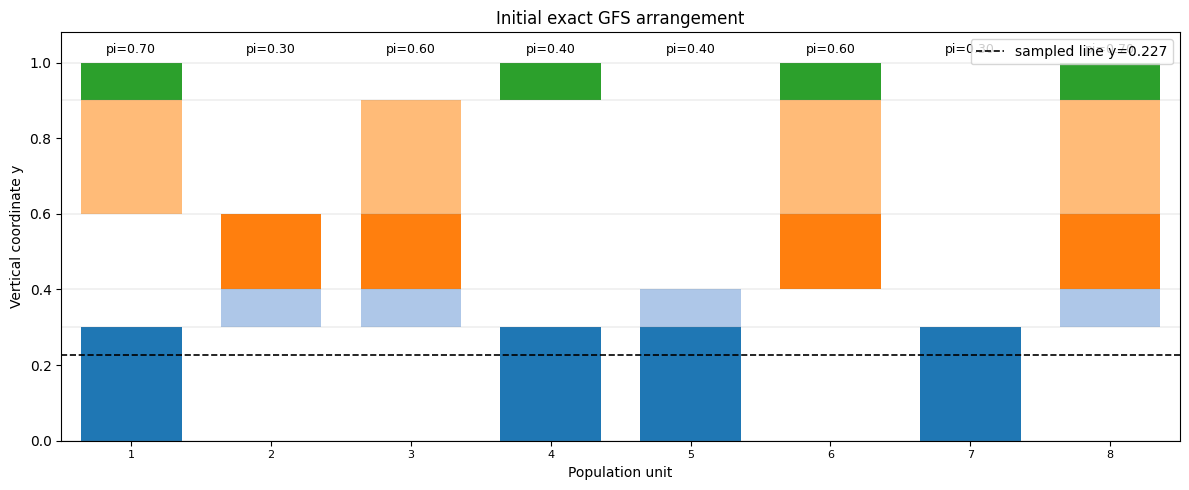

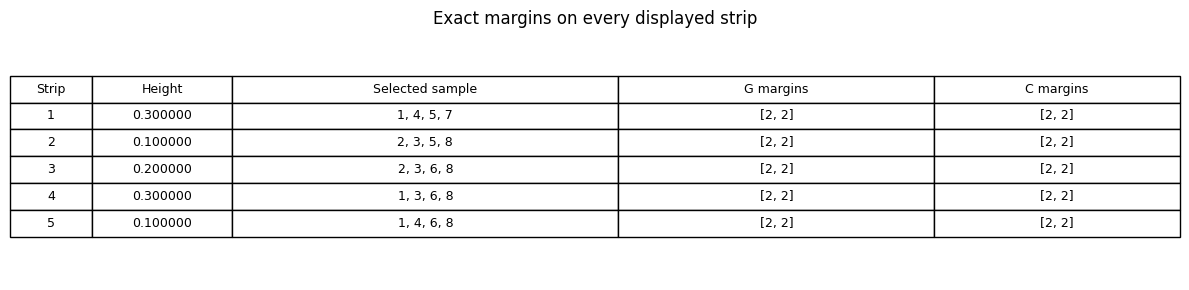

In [12]:
if data_available:
    initial_gfs_figure, ax = plt.subplots(figsize=(12, 5))
    plot_gfs(initial_strips, pi_original, "Initial exact GFS arrangement", ax=ax,
             unit_labels=population["unit"], max_units=32, line=random_line)
    initial_gfs_figure.tight_layout()
    plt.show()
    initial_margin_figure = plot_strip_margins(initial_strips, X, H)
    plt.show()

## 5. Derive the sampling design **after** construction

**THESE $p_s$ VALUES WERE NOT INPUTS. THEY EMERGED FROM THE GFS ARRANGEMENT.**

The probability of a strip is its height because the line is uniform on $[0,1]$.
If nonadjacent strips produce the same binary sample, their heights are added
when deriving the design. This aggregation does not alter the graphical arrangement.
The support here means only samples actually constructed, not all feasible samples.

In [13]:
def derive_design(strips):
    aggregated = {}
    for strip in strips:
        key = tuple(int(value) for value in strip["sample"])
        aggregated[key] = aggregated.get(key, 0.0) + strip["height"]
    samples = np.array(list(aggregated), dtype=int)
    probabilities = np.array(list(aggregated.values()), dtype=float)
    assert np.all(probabilities > 0) and abs(probabilities.sum() - 1) <= TOL
    table = pd.DataFrame({"sample": [tuple(np.flatnonzero(s) + 1) for s in samples],
                          "probability": probabilities})
    return samples, probabilities, table

In [14]:
if data_available:
    initial_design_samples, initial_design_p, initial_design = derive_design(initial_strips)
    display(initial_design if POPULATION == "SMALL" else initial_design.head(12))
    np.testing.assert_allclose(initial_design_p @ initial_design_samples, pi_original, atol=TOL, rtol=0)
    print(f"Induced probabilities sum to {initial_design_p.sum():.12f}; "
          f"{len(initial_design)} distinct samples. First-order probabilities reconstructed again.")

,sample,probability
0,"(1, 4, 5, 7)",0.3
1,"(2, 3, 5, 8)",0.1
2,"(2, 3, 6, 8)",0.2
3,"(1, 3, 6, 8)",0.3
4,"(1, 4, 6, 8)",0.1


Induced probabilities sum to 1.000000000000; 5 distinct samples. First-order probabilities reconstructed again.


## 6. Legal exchanges of equal-height substrips

Choose strips A and B, disjoint differences $A\setminus B$ and $B\setminus A$,
and unit sets $K\subset A\setminus B$, $L\subset B\setminus A$. Require
$\sum_{k\in K}x_k=\sum_{l\in L}x_l$. Exchange height
$0<\delta\leq\min(h_A,h_B)$:

$$s'_A=s_A-1_K+1_L,\qquad s'_B=s_B-1_L+1_K.$$

The incidence equality preserves each strip's category margins. The identity
$s'_A+s'_B=s_A+s_B$ preserves each unit's total length because both exchanged
pieces have **the same height**. Remainders stay at their original vertical positions;
we place the exchanged piece at the top of each source strip. Adjacent identical
pieces can be merged. This rearrangement is not an entropy optimization.

**Type 1:** one unit on each side from the same cell.
**Type 2:** two diagonal cells from A and the two opposite cells from B in a
$2\times2$ rectangle. This can change individual cell counts while preserving
both category margins. A design need not admit either particular move type;
absence of a move is reported, not treated as proof that no rearrangement exists.

In [15]:
def cell_indices(X, H):
    return np.argmax(X[:, :H], axis=1), np.argmax(X[:, H:], axis=1)


def difference_cells(A, B, X, H):
    g, c = cell_indices(X, H)
    only_A, only_B = {}, {}
    for k in np.flatnonzero((A == 1) & (B == 0)):
        only_A.setdefault((int(g[k]), int(c[k])), []).append(int(k))
    for k in np.flatnonzero((B == 1) & (A == 0)):
        only_B.setdefault((int(g[k]), int(c[k])), []).append(int(k))
    return only_A, only_B


def find_same_cell_exchange(A, B, X, H):
    only_A, only_B = difference_cells(A, B, X, H)
    for cell in sorted(only_A.keys() & only_B.keys()):
        return [only_A[cell][0]], [only_B[cell][0]]
    return None


def find_rectangle_exchange(A, B, X, H):
    only_A, only_B = difference_cells(A, B, X, H)
    for g1, g2 in combinations(range(H), 2):
        for c1, c2 in combinations(range(X.shape[1] - H), 2):
            diagonal = [(g1, c1), (g2, c2)]
            opposite = [(g1, c2), (g2, c1)]
            for cells_A, cells_B in [(diagonal, opposite), (opposite, diagonal)]:
                if all(cell in only_A for cell in cells_A) and all(cell in only_B for cell in cells_B):
                    K = [only_A[cell][0] for cell in cells_A]
                    L = [only_B[cell][0] for cell in cells_B]
                    np.testing.assert_array_equal(X[K].sum(axis=0), X[L].sum(axis=0))
                    return K, L
    return None


def merge_adjacent_strips(strips):
    merged = []
    for strip in strips:
        if strip["height"] == 0:
            continue
        assert strip["height"] > 0
        if merged and np.array_equal(merged[-1]["sample"], strip["sample"]):
            merged[-1]["height"] += strip["height"]
        else:
            merged.append({"height": float(strip["height"]), "sample": strip["sample"].copy()})
    return merged


def apply_exchange(strips, index_A, index_B, delta, K, L, *, X, merge=True):
    if index_A == index_B or not (0 <= index_A < len(strips) and 0 <= index_B < len(strips)):
        raise ValueError("Select two distinct valid strips")
    A = strips[index_A]["sample"].copy()
    B = strips[index_B]["sample"].copy()
    K, L = list(K), list(L)
    if not np.isfinite(delta) or not 0 < delta <= min(strips[index_A]["height"], strips[index_B]["height"]):
        raise ValueError("Exchange delta must be positive and fit inside both strips")
    if (not K or not L or len(set(K)) != len(K) or len(set(L)) != len(L)
            or any(k < 0 or k >= len(A) for k in K + L)):
        raise ValueError("Exchange unit sets must be nonempty, unique and in range")
    if not (np.all(A[K] == 1) and np.all(B[K] == 0)
            and np.all(B[L] == 1) and np.all(A[L] == 0)):
        raise ValueError("K and L must belong to the respective exclusive sample differences")
    if not np.array_equal(X[K].sum(axis=0), X[L].sum(axis=0)):
        raise ValueError("Exchange incidence totals differ; category margins would change")
    A_new, B_new = A.copy(), B.copy()
    A_new[K], A_new[L] = 0, 1
    B_new[L], B_new[K] = 0, 1
    np.testing.assert_array_equal(A_new + B_new, A + B)
    np.testing.assert_array_equal(X.T @ A_new, X.T @ A)
    np.testing.assert_array_equal(X.T @ B_new, X.T @ B)
    updated = []
    for index, strip in enumerate(strips):
        if index in (index_A, index_B):
            remainder = strip["height"] - delta
            if remainder > 0:
                updated.append({"height": remainder, "sample": strip["sample"].copy()})
            updated.append({"height": delta,
                            "sample": A_new.copy() if index == index_A else B_new.copy()})
        else:
            updated.append({"height": strip["height"], "sample": strip["sample"].copy()})
    if merge:
        updated = merge_adjacent_strips(updated)
    info = {"strips_selected": (index_A + 1, index_B + 1), "delta": delta,
            "K": K, "L": L, "A_before": A, "B_before": B,
            "A_after": A_new, "B_after": B_new,
            "margins_A_before": X.T @ A, "margins_B_before": X.T @ B,
            "margins_A_after": X.T @ A_new, "margins_B_after": X.T @ B_new}
    return updated, info


def run_exchanges(strips, X, pi_original, m, H, count, seed=12345, verbose=False):
    assert isinstance(count, int) and count >= 0
    current = [{"height": strip["height"], "sample": strip["sample"].copy()} for strip in strips]
    verify_gfs(current, X, pi_original, m, H)
    rng = np.random.default_rng(seed)
    log = []
    finders = {"same_cell": find_same_cell_exchange, "rectangle": find_rectangle_exchange}
    for number in range(1, count + 1):
        pairs = list(combinations(range(len(current)), 2))
        rng.shuffle(pairs)
        preferred = ["same_cell", "rectangle"] if number % 2 else ["rectangle", "same_cell"]
        proposal = None
        for kind in preferred:
            for a, b in pairs:
                move = finders[kind](current[a]["sample"], current[b]["sample"], X, H)
                if move is not None:
                    proposal = (kind, a, b, move)
                    break
            if proposal is not None:
                break
        if proposal is None:
            print(f"Stopped after {len(log)} exchanges: no same-cell or rectangle move remains.")
            break
        kind, a, b, (K, L) = proposal
        # Half of the smaller height deliberately demonstrates substrip splitting.
        delta = .5 * min(current[a]["height"], current[b]["height"])
        pi_before = reconstruct_pi(current)
        current, info = apply_exchange(current, a, b, delta, K, L, X=X)
        checks = verify_gfs(current, X, pi_original, m, H)
        pi_after = reconstruct_pi(current)
        np.testing.assert_allclose(pi_after, pi_before, atol=TOL, rtol=0)
        info.update({"exchange": number, "kind": kind,
                     "max_pi_change": float(np.max(np.abs(pi_after - pi_before))),
                     "max_error_original_pi": checks["max_pi_error"], "strip_count": len(current)})
        log.append(info)
        if verbose and number <= 6:
            print(f"Exchange {number}: {kind} | strips {info['strips_selected']} | delta={delta:.8g}")
            print("K units (A to B):", [k + 1 for k in K], "| L units (B to A):", [k + 1 for k in L])
            display(pd.DataFrame({"unit": np.arange(1, len(pi_original) + 1),
                                  "A before": info["A_before"], "B before": info["B_before"],
                                  "A after": info["A_after"], "B after": info["B_after"]}))
            display(pd.DataFrame({"A before": info["margins_A_before"], "A after": info["margins_A_after"],
                                  "B before": info["margins_B_before"], "B after": info["margins_B_after"]}))
            print("Maximum absolute change in pi:", info["max_pi_change"],
                  "| Maximum error against ORIGINAL pi:", info["max_error_original_pi"])
    return current, pd.DataFrame(log)

## 7. Perform and verify every exchange

We try alternating move types; if the preferred type is unavailable, we try the
other. There is no diagnostic-based acceptance rule. Every accepted exchange checks
total height, all exact strip margins, binary samples, positive heights and
reconstruction of the **original** prescribed lengths. SMALL prints the first six
exchanges; the complete `exchange_log` retains all before/after vectors and margins.
Strip numbers refer to the arrangement immediately before that exchange, since
splitting changes later strip numbers. `K` and `L` in the stored log are zero-based;
printed unit labels are one-based.

Exchange 1: same_cell | strips (2, 3) | delta=0.05
K units (A to B): [5] | L units (B to A): [6]


,unit,A before,B before,A after,B after
0,1,0,0,0,0
1,2,1,1,1,1
2,3,1,1,1,1
3,4,0,0,0,0
4,5,1,0,0,1
5,6,0,1,1,0
6,7,0,0,0,0
7,8,1,1,1,1


,A before,A after,B before,B after
0,2,2,2,2
1,2,2,2,2
2,2,2,2,2
3,2,2,2,2


Maximum absolute change in pi: 0.0 | Maximum error against ORIGINAL pi: 0.0
Exchange 2: rectangle | strips (1, 3) | delta=0.1
K units (A to B): [1, 7] | L units (B to A): [3, 6]


,unit,A before,B before,A after,B after
0,1,1,0,0,1
1,2,0,1,0,1
2,3,0,1,1,0
3,4,1,0,1,0
4,5,1,0,1,0
5,6,0,1,1,0
6,7,1,0,0,1
7,8,0,1,0,1


,A before,A after,B before,B after
0,2,2,2,2
1,2,2,2,2
2,2,2,2,2
3,2,2,2,2


... (12 outputs left out)

Maximum absolute change in pi: 0.0 | Maximum error against ORIGINAL pi: 0.0


,After exchanges
strips,34
total_height,1.0
exact_margins_all_strips,True
binary_all_samples,True
positive_all_heights,True
sample_size,4
max_pi_error,0.0


Accepted 20 exchanges in 0.0999 seconds.


,exchange,kind,strips_selected,delta,max_pi_change,max_error_original_pi,strip_count
0,1,same_cell,"(2, 3)",0.050000,0.000000e+00,0.000000e+00,6
1,2,rectangle,"(1, 3)",0.100000,0.000000e+00,0.000000e+00,8
2,3,same_cell,"(6, 8)",0.025000,0.000000e+00,0.000000e+00,10
3,4,rectangle,"(1, 4)",0.050000,0.000000e+00,0.000000e+00,10
4,5,same_cell,"(6, 7)",0.012500,0.000000e+00,0.000000e+00,11
5,6,rectangle,"(5, 9)",0.075000,0.000000e+00,0.000000e+00,13
6,7,same_cell,"(3, 10)",0.025000,1.110223e-16,1.110223e-16,15
7,8,rectangle,"(4, 6)",0.012500,0.000000e+00,1.110223e-16,17
8,9,same_cell,"(3, 14)",0.012500,0.000000e+00,1.110223e-16,19
9,10,rectangle,"(17, 18)",0.037500,0.000000e+00,1.110223e-16,20


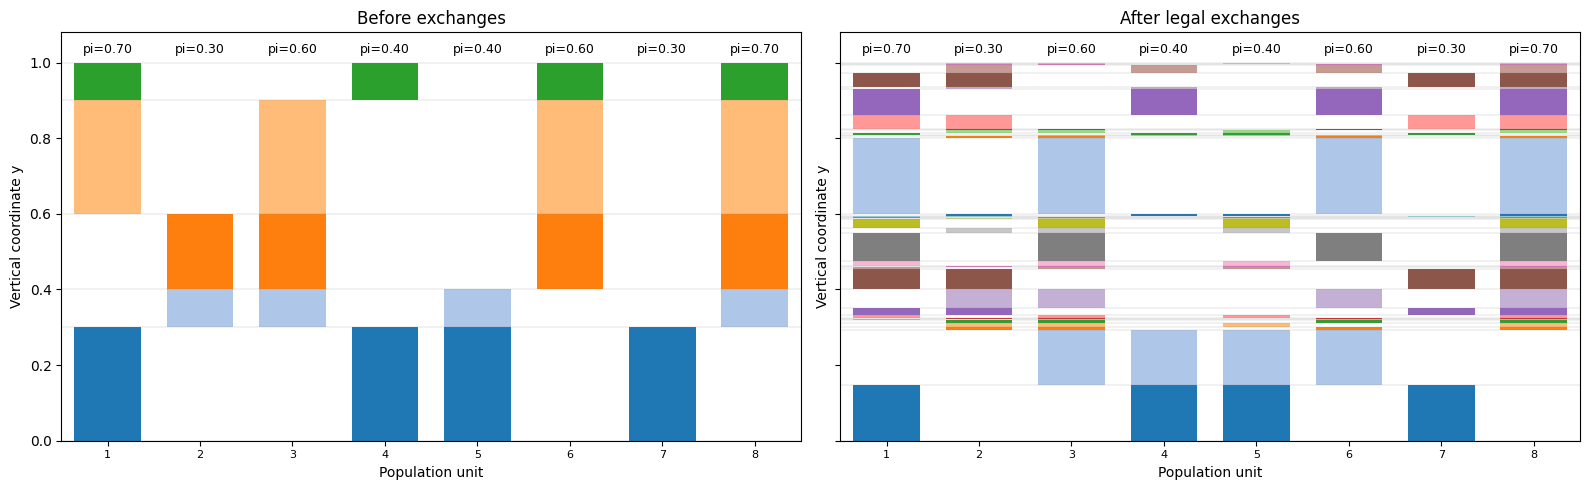

In [16]:
if data_available:
    exchange_start = perf_counter()
    final_strips, exchange_log = run_exchanges(
        initial_strips, X, pi_original, m, H,
        N_EXCHANGES if RUN_EXCHANGES else 0, seed=RANDOM_SEED,
        verbose=(VERBOSE and POPULATION == "SMALL"))
    exchange_seconds = perf_counter() - exchange_start
    final_checks = verify_gfs(final_strips, X, pi_original, m, H)
    display(pd.Series(final_checks, name="After exchanges").to_frame())
    print(f"Accepted {len(exchange_log)} exchanges in {exchange_seconds:.4f} seconds.")
    if len(exchange_log):
        display(exchange_log[["exchange", "kind", "strips_selected", "delta", "max_pi_change",
                              "max_error_original_pi", "strip_count"]])
    before_after_figure, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
    plot_gfs(initial_strips, pi_original, "Before exchanges", ax=axes[0],
             unit_labels=population["unit"], max_units=32)
    plot_gfs(final_strips, pi_original, "After legal exchanges", ax=axes[1],
             unit_labels=population["unit"], max_units=32)
    before_after_figure.tight_layout()
    plt.show()

## 8. Diagnostics, without optimization

For the constructed support, $\pi_{kl}=\sum_s p_s s_k s_l$.
Its diagonal equals $\pi_k$. Zero counts below count **unordered off-diagonal
pairs** ($k<l$), both exact zeros and values within $10^{-10}$ of zero.
Shannon entropy uses natural logarithms (nats). It may rise or fall after a legal
exchange; no step selects or accepts exchanges based on entropy.
These moves need not connect all possible exact-margin designs.

In [17]:
def design_diagnostics(strips):
    samples, probabilities, design = derive_design(strips)
    first_order = probabilities @ samples
    second_order = samples.T @ (probabilities[:, None] * samples)
    np.testing.assert_allclose(np.diag(second_order), first_order, atol=TOL, rtol=0)
    upper_pairs = second_order[np.triu_indices(len(first_order), k=1)]
    assert np.all(second_order >= 0)
    assert np.all(second_order <= np.minimum.outer(first_order, first_order) + TOL)
    summary = {"strips": len(strips), "distinct_samples": len(probabilities),
               "probability_sum": probabilities.sum(), "exact_zero_pairs": int(np.sum(upper_pairs == 0)),
               "near_zero_pairs": int(np.sum(upper_pairs <= TOL)),
               "entropy_nats": float(-np.sum(probabilities * np.log(probabilities)))}
    return {"summary": summary, "design": design, "pi": first_order, "pi_kl": second_order}

,strips,distinct_samples,probability_sum,exact_zero_pairs,near_zero_pairs,entropy_nats
Initial,5.0,5.0,1.0,8.0,8.0,1.504788
After exchanges,34.0,10.0,1.0,2.0,2.0,2.002060


Final induced p_s (complete table retained as final_diagnostics['design']):


,sample,probability
0,"(1, 4, 5, 7)",0.150000
1,"(3, 4, 5, 6)",0.150000
2,"(2, 3, 6, 8)",0.077344
3,"(2, 3, 5, 8)",0.041406
4,"(1, 3, 6, 8)",0.278906
5,"(1, 3, 5, 8)",0.052344
6,"(1, 2, 7, 8)",0.150000
7,"(2, 4, 5, 8)",0.006250
8,"(1, 4, 6, 8)",0.068750
9,"(2, 4, 6, 8)",0.025000


,unit,prescribed pi,initial pi,after exchanges pi
0,1,0.7,0.7,0.7
1,2,0.3,0.3,0.3
2,3,0.6,0.6,0.6
3,4,0.4,0.4,0.4
4,5,0.4,0.4,0.4
5,6,0.6,0.6,0.6
6,7,0.3,0.3,0.3
7,8,0.7,0.7,0.7


Initial second-order matrix pi_kl:


unit,1,2,3,4,5,6,7,8
unit,,,,,,,,
1,0.7,0.0,0.3,0.4,0.3,0.4,0.3,0.4
2,0.0,0.3,0.3,0.0,0.1,0.2,0.0,0.3
3,0.3,0.3,0.6,0.0,0.1,0.5,0.0,0.6
4,0.4,0.0,0.0,0.4,0.3,0.1,0.3,0.1
5,0.3,0.1,0.1,0.3,0.4,0.0,0.3,0.1
6,0.4,0.2,0.5,0.1,0.0,0.6,0.0,0.6
7,0.3,0.0,0.0,0.3,0.3,0.0,0.3,0.0
8,0.4,0.3,0.6,0.1,0.1,0.6,0.0,0.7


After-exchange second-order matrix pi_kl:


unit,1,2,3,4,5,6,7,8
unit,,,,,,,,
1,0.700000,0.150000,0.33125,0.21875,0.202344,0.347656,0.30,0.55
2,0.150000,0.300000,0.11875,0.03125,0.047656,0.102344,0.15,0.30
3,0.331250,0.118750,0.60000,0.15000,0.243750,0.506250,0.00,0.45
4,0.218750,0.031250,0.15000,0.40000,0.306250,0.243750,0.15,0.10
5,0.202344,0.047656,0.24375,0.30625,0.400000,0.150000,0.15,0.10
6,0.347656,0.102344,0.50625,0.24375,0.150000,0.600000,0.00,0.45
7,0.300000,0.150000,0.00000,0.15000,0.150000,0.000000,0.30,0.15
8,0.550000,0.300000,0.45000,0.10000,0.100000,0.450000,0.15,0.70


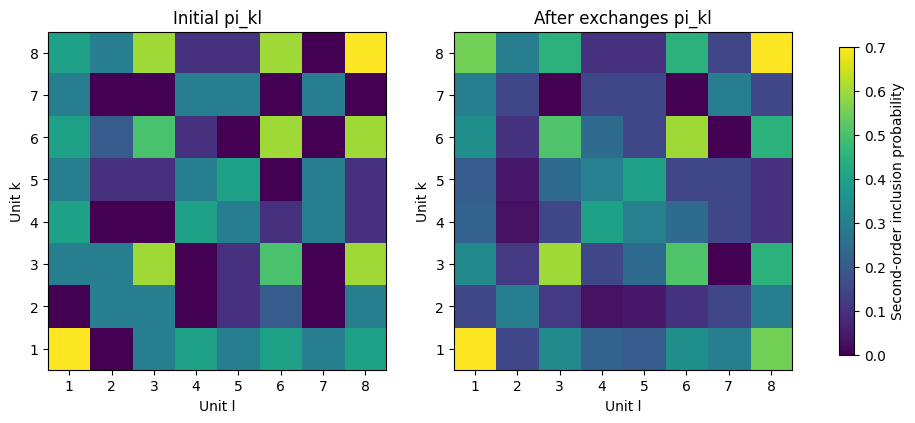

In [18]:
if data_available:
    initial_diagnostics = design_diagnostics(initial_strips)
    final_diagnostics = design_diagnostics(final_strips)
    diagnostic_summary = pd.DataFrame({"Initial": initial_diagnostics["summary"],
                                       "After exchanges": final_diagnostics["summary"]}).T
    display(diagnostic_summary)
    print("Final induced p_s (complete table retained as final_diagnostics['design']):")
    display(final_diagnostics["design"] if POPULATION == "SMALL" else final_diagnostics["design"].head(12))
    np.testing.assert_allclose(final_diagnostics["pi"], pi_original, atol=TOL, rtol=0)
    if POPULATION == "SMALL":
        display(pd.DataFrame({"unit": population["unit"], "prescribed pi": pi_original,
                              "initial pi": initial_diagnostics["pi"], "after exchanges pi": final_diagnostics["pi"]}))
        print("Initial second-order matrix pi_kl:")
        display(pd.DataFrame(initial_diagnostics["pi_kl"], index=population["unit"], columns=population["unit"]))
        print("After-exchange second-order matrix pi_kl:")
        display(pd.DataFrame(final_diagnostics["pi_kl"], index=population["unit"], columns=population["unit"]))
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    scale = max(initial_diagnostics["pi_kl"].max(), final_diagnostics["pi_kl"].max())
    for ax, diagnostics, title in zip(axes, [initial_diagnostics, final_diagnostics], ["Initial pi_kl", "After exchanges pi_kl"]):
        heatmap = ax.imshow(diagnostics["pi_kl"], vmin=0, vmax=scale, cmap="viridis", origin="lower",
                            extent=(.5, N + .5, .5, N + .5))
        ax.set(title=title, xlabel="Unit l", ylabel="Unit k")
    fig.colorbar(heatmap, ax=axes.tolist(), label="Second-order inclusion probability", shrink=.8)
    plt.show()

## 9. Switch to the original MU284

Change the top configuration to `POPULATION = "MU284"` and rerun everything.
The same `construct_exact_gfs`, `find_exact_sample_flow`, `apply_exchange` and
verification functions are used unchanged. Only input preparation differs.

For the original population: $N=284$, $n=100$, eight REG levels and four P85
quartile CAT levels give 12 dummy columns. The original P85 breaks are
$3,10,16,31,653$. Counts can differ across quartiles because P85 has ties.
We begin with $\pi_k^{init}=100/284$, display $m^{init}=X^T\pi^{init}$,
round the margins transparently, then rake to those integer targets. The
resulting **calibrated $\pi$** is the direct input to the graphical construction.

Inspect the exact category table in section 1 and the calibration trace below.
The stopping criterion is the larger of $10^{-16}$ and $8N$ times the working
dtype's machine epsilon. This accounts for roundoff in category sums, including
platforms where `longdouble` equals float64. The actual threshold is retained in
`raking_history["tolerance"]` and remains tighter than the $10^{-10}$ reconstruction
check. Conditional residual checks explicitly account for error amplification by $1/L$. Raking is a calibration procedure, not a sampling-design optimizer.

In [19]:
if data_available and POPULATION == "MU284":
    display(raking_history.head(8))
    display(raking_history.tail(3))
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.semilogy(raking_history["iteration"], np.maximum(raking_history["margin_error"], 1e-16), marker=".")
    ax.set(xlabel="Raking iteration", ylabel="Maximum absolute margin error", title="Calibration convergence")
    ax.axhline(raking_history["tolerance"].iloc[0], color="gray", linestyle="--")
    fig.tight_layout()
    plt.show()
else:
    print("MU284 calibration output appears when the top population switch is MU284.")

MU284 calibration output appears when the top population switch is MU284.


## 10. Compact MU284 results

The first panel checks **all units**, including the units omitted from the compact
segment plots. The second panel displays calibration ranges. Timing includes data
preparation, construction, displays and exchanges up to this section; individual
construction and exchange times are reported separately.

In [20]:
if data_available and POPULATION == "MU284":
    mu284_summary = pd.Series({
        "N": N, "n": n, "REG_categories": H, "CAT_categories": X.shape[1] - H,
        "min_calibrated_pi": pi_original.min(), "max_calibrated_pi": pi_original.max(),
        "calibrated_margin_error": float(np.max(np.abs(X.T @ pi_original - m))),
        "initial_strips": len(initial_strips), "final_strips": len(final_strips),
        "initial_distinct_samples": initial_diagnostics["summary"]["distinct_samples"],
        "final_distinct_samples": final_diagnostics["summary"]["distinct_samples"],
        "accepted_exchanges": len(exchange_log), "all_strip_margins_exact": True,
        "initial_max_pi_error": initial_checks["max_pi_error"],
        "final_max_pi_error": final_checks["max_pi_error"],
        "construction_seconds": construction_seconds, "exchange_seconds": exchange_seconds,
        "workflow_seconds_so_far": perf_counter() - workflow_start,
    }, name="Original MU284 results")
    display(mu284_summary.to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(population["unit"], pi_original, label="Prescribed", linewidth=2)
    axes[0].plot(population["unit"], reconstruct_pi(final_strips), linestyle="none", marker=".", label="Reconstructed")
    axes[0].set(xlabel="Unit", ylabel="Inclusion probability", title="All 284 units retain their lengths")
    axes[0].legend()
    axes[1].hist(pi_original, bins=20, edgecolor="white")
    axes[1].set(xlabel="Calibrated pi", ylabel="Number of units", title="Distribution of prescribed lengths")
    fig.tight_layout()
    plt.show()

## 11. Try to break the construction with random feasible inputs

The stress tests generate $\pi$ directly without first drawing design probabilities.
Start with two units per cell and length $1/2$ each. Each cell initially contributes
one, so integer G margins are the number of C categories, and vice versa.
Random same-cell transfers and rectangle circulations change the **length vector**
while preserving $X^T\pi$. Moves are limited by the $[0,1]$ bounds. Some move all the
way to a boundary to exercise forbidden/forced units. The tests vary the number
of categories and scramble unit order. They test construction and both available
exchange types against the original lengths.

We also test all-zero/all-one vectors and a population with empty cross cells.
Enumeration is used only for independent SMALL flow checks. A failure prints its
stage, the complete population, $X$, $\pi$, $m$ and seed, then **raises** the error.
No failed counterexample is skipped. Passing these tests cannot establish the
claim for every possible input or certify numerical robustness for arbitrary sizes.

In [21]:
def random_feasible_population(rng, H=2, J=2):
    rows = []
    for g in range(H):
        for c in range(J):
            for replicate in range(2):
                rows.append({"G": f"G{g+1}", "C": f"C{c+1}", "pi": .5})
    pop = pd.DataFrame(rows)
    X, _, split = build_disjunctive_matrix(pop)
    pi = pop["pi"].to_numpy().copy()
    for step in range(40):
        direction = np.zeros(len(pi))
        if step % 2 == 0:
            cell = int(rng.integers(H * J))
            plus, minus = [2 * cell], [2 * cell + 1]
        else:
            g1, g2 = sorted(rng.choice(H, 2, replace=False))
            c1, c2 = sorted(rng.choice(J, 2, replace=False))
            plus = [2 * (g1 * J + c1), 2 * (g2 * J + c2)]
            minus = [2 * (g1 * J + c2), 2 * (g2 * J + c1)]
        direction[plus], direction[minus] = 1, -1
        if rng.random() < .5:
            direction *= -1
        np.testing.assert_array_equal(X.T @ direction, np.zeros(X.shape[1]))
        positive, negative = direction > 0, direction < 0
        limit = min(np.min(1 - pi[positive]), np.min(pi[negative]))
        fraction = 1.0 if step % 7 == 0 else float(rng.uniform(.05, .95))
        pi += fraction * limit * direction
        pi = np.clip(pi, 0, 1)  # only machine-roundoff at a deliberately reached boundary
    pop["pi"] = pi
    pop = pop.iloc[rng.permutation(len(pop))].reset_index(drop=True)
    pop["unit"] = np.arange(1, len(pop) + 1)
    return pop[["unit", "G", "C", "pi"]]


def run_stress_tests(seed=12345, count=30):
    rng = np.random.default_rng(seed)
    cases = []
    for case in range(count):
        H, J = int(rng.integers(2, 5)), int(rng.integers(2, 5))
        cases.append((f"random_{case+1}", random_feasible_population(rng, H, J)))
    for value in [0., 1.]:
        pop = make_small_population()
        pop["pi"] = value
        cases.append((f"all_{value:g}", pop))
    sparse = pd.DataFrame({"unit": [1,2,3,4], "G": ["G1","G1","G2","G2"],
                           "C": ["C1","C1","C2","C2"], "pi": [.2,.8,.65,.35]})
    cases.append(("empty_cross_cells", sparse))
    results = []
    for number, (name, pop) in enumerate(cases, start=1):
        stage = "input validation"
        X = m = None
        pi = pop["pi"].to_numpy()
        try:
            X, _, H = build_disjunctive_matrix(pop)
            m = check_integer_margins(X, pi, H)
            stage = "residual construction"
            strips, trace = construct_exact_gfs(X, pi, m, H, seed=seed + number)
            stage = "initial graphical verification"
            checks = verify_gfs(strips, X, pi, m, H)
            stage = "legal exchanges and per-exchange verification"
            exchanged, log = run_exchanges(strips, X, pi, m, H, 4, seed=seed + number)
            checks_after = verify_gfs(exchanged, X, pi, m, H)
            results.append({"case": name, "N": len(pi), "H": H, "J": X.shape[1] - H,
                            "n": m[:H].sum(), "strips": len(strips), "exchanges": len(log),
                            "max_pi_error": checks["max_pi_error"],
                            "after_pi_error": checks_after["max_pi_error"], "passed": True})
        except Exception:
            print(f"COUNTEREXAMPLE | case={name} | seed={seed} | construction_seed={seed+number} | stage={stage}")
            print(pop.to_string(index=False))
            print("X =", None if X is None else X.tolist())
            print("pi =", pi.tolist())
            print("m =", None if m is None else m.tolist())
            raise
    return pd.DataFrame(results)

In [22]:
stress_start = perf_counter()
stress_results = run_stress_tests(seed=RANDOM_SEED, count=30)
display(stress_results)
assert stress_results["passed"].all()
print(f"All {len(stress_results)} tests passed in {perf_counter()-stress_start:.4f} seconds.")
print("Maximum reconstruction error across stress cases:", stress_results["max_pi_error"].max())
print("Maximum error after stress exchanges:", stress_results["after_pi_error"].max())
if data_available:
    display(Markdown(
        f"**This executed run supports the claim for the tested inputs:** {POPULATION}, "
        f"{len(initial_strips)} initial strips, {len(exchange_log)} legal exchanges, "
        f"and {len(stress_results)} passing stress cases. Every retained sample has exact "
        f"integer margins; maximum final length error in the selected population is "
        f"{final_checks['max_pi_error']:.3g}. This is computational evidence, not a proof."))
else:
    display(Markdown(f"**The {len(stress_results)} executed synthetic tests support the claim "
                     "for those inputs. MU284 was unavailable and was not tested in this run.**"))

Stopped after 0 exchanges: no same-cell or rectangle move remains.
Stopped after 0 exchanges: no same-cell or rectangle move remains.


,case,N,H,J,n,strips,exchanges,max_pi_error,after_pi_error,passed
0,random_1,16,4,2,8,10,4,1.110223e-16,1.110223e-16,True
1,random_2,12,2,3,6,8,4,1.110223e-16,1.110223e-16,True
2,random_3,16,4,2,8,8,4,5.551115e-17,5.551115e-17,True
3,random_4,16,4,2,8,10,4,3.330669e-16,3.330669e-16,True
4,random_5,12,3,2,6,7,4,2.220446e-16,2.220446e-16,True
5,random_6,12,3,2,6,9,4,3.885781e-16,3.885781e-16,True
6,random_7,32,4,4,16,23,4,2.220446e-16,2.220446e-16,True
7,random_8,24,3,4,12,15,4,3.365364e-16,3.365364e-16,True
8,random_9,16,2,4,8,12,4,2.220446e-16,2.220446e-16,True
9,random_10,32,4,4,16,23,4,3.330669e-16,3.330669e-16,True


All 33 tests passed in 1.1841 seconds.
Maximum reconstruction error across stress cases: 4.996003610813204e-16
Maximum error after stress exchanges: 4.996003610813204e-16


**This executed run supports the claim for the tested inputs:** SMALL, 5 initial strips, 20 legal exchanges, and 33 passing stress cases. Every retained sample has exact integer margins; maximum final length error in the selected population is 1.11e-16. This is computational evidence, not a proof.

## Scientific conclusion: what the experiments establish

> Given two categorical variables and prescribed first-order inclusion probabilities
> $\pi$ satisfying $X^T\pi=m$ with integer margins, we can construct a segmented GFS
> arrangement directly from $X$ and $\pi$ such that every horizontal line gives an
> exact double-stratified sample and every unit retains total graphical length $\pi_k$.

**The default SMALL computational experiments support this claim for the tested
inputs; they do not contradict it.** The executed result immediately above states
which population and stress cases actually ran. When MU284 is selected and loaded,
its calibrated prescribed lengths undergo the same checks. The notebook stops on
any detected counterexample instead of replacing a failure by a success statement.
The required hypotheses also include $0\leq\pi_k\leq1$ and valid two-classification
incidence rows. Length preservation is checked to the stated numerical tolerance;
integer strip margins and binary membership are checked exactly.

Distinguish three questions:

1. **Existence of some arrangement.** The fractional bipartite b-matching viewpoint
   gives a mathematical route to studying existence. Finite successful experiments
   alone do not prove the universal claim.
2. **This residual construction.** It chooses one support-compatible integral flow,
   places the largest safe strip, and repeats. The boundary argument explains its
   intended exact-arithmetic progress; this implementation additionally has finite
   precision and an explicit bounded numerical-tail convention. Our tests check it,
   rather than proving a theorem about every numerical input.
3. **Later rearrangement or optimization.** Equal-height legal exchanges retain
   lengths and margins but may change joint inclusion probabilities, support and
   entropy. Neither exchange reachability nor optimality is established here.
   There is **no entropy optimization** in this notebook.

Continue research by retaining genuine failing counterexamples, enlarging stress
families and studying existence and numerical stability separately. Successful
plots and simulations are evidence for the implemented construction, not a proof.